# PUN clearing — MGP, 4 May 2010

Full-day results are cached in `results/20100504_hourly.csv`; delete it to re-solve (~7 min).

In [1]:
import logging
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pyomo.environ import Var, Constraint, value

from pun_clearing.conf import options
from pun_clearing.dataio.gme_importer import load_day
from pun_clearing.model.pun_model import build_model, extract_solution, solve_model
from pun_clearing.run_hourly import solve_hours

logging.disable(logging.WARNING)
pd.set_option("display.precision", 6)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, RESULTS_DIR = ROOT / "data", ROOT / "results"
DATE = "20100504"
PUN_ZONES = list(options.PUN_ZONES)

# plot style
BLUE, GREY, ORANGE = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## Data

In [2]:
gme = load_day(DATA_DIR, DATE)
hourly_data, real_prices = gme.hours, gme.real_prices

ZONE_TYPES = {
    **{z: "Italian zone (PUN)" for z in PUN_ZONES},
    **{z: "foreign zone" for z in ["AUST", "CORS", "COAC", "FRAN", "GREC", "SLOV", "SVIZ"]},
    **{z: "limited production pole" for z in ["BRNN", "FOGN", "MFTV", "PRGP", "ROSN"]},
}
zones = pd.DataFrame(
    [(z.name, ZONE_TYPES.get(z.name, "?")) for z in hourly_data[1].zones.values()],
    columns=["zone", "type"]).sort_values(["type", "zone"])
n_links = len({tuple(sorted(link)) for link in hourly_data[1].flow_limits})
print(f"{len(zones)} zones, {n_links} interconnections")
zones.groupby("type")["zone"].apply(", ".join).to_frame("zones")

18 zones, 18 interconnections


,zones
type,
Italian zone (PUN),"CNOR, CSUD, NORD, SARD, SICI, SUD"
foreign zone,"AUST, COAC, CORS, FRAN, GREC, SLOV, SVIZ"
limited production pole,"BRNN, FOGN, MFTV, PRGP, ROSN"


In [3]:
orders = pd.DataFrame([
    {"hour": h,
     "supply offers": len(d.supply_bids),
     "PUN bids": len(d.pun_bids),
     "  of which without price limit": sum(b.price >= options.MAX_PRICE for b in d.pun_bids),
     "non-PUN bids": len(d.demand_bids)}
    for h, d in hourly_data.items()]).set_index("hour")
pd.concat([orders.head(4), orders.tail(2), orders.sum().to_frame("day total").T])

,supply offers,PUN bids,of which without price limit,non-PUN bids
1,1207,441,433,41
2,1199,440,432,50
3,1189,437,429,48
4,1188,440,428,48
23,1273,441,429,36
24,1239,434,426,37
day total,30802,10560,10334,972


## All 24 hours

In [4]:
RESULTS_FILE = RESULTS_DIR / f"{DATE}_hourly.csv"


def classify(share):
    return "ITM" if share > 1 - 1e-6 else "ATM" if share > 1e-6 else "OTM"


def hour_row(hour, sol):
    real = real_prices[hour]
    row = {"hour": hour, "pun_model": sol.pun_price, "pun_gme": real["PUN"]}
    for z in PUN_ZONES:
        row[f"{z}_model"] = sol.zonal_prices[gme.zone_ids[z]]
        row[f"{z}_gme"] = real[z]
    classes = Counter(classify(a) for a in sol.acceptance.pun)
    row.update({
        "pun_demand_mwh": sum(b.volume * a
                              for b, a in zip(hourly_data[hour].pun_bids, sol.acceptance.pun)),
        "itm_bids": classes["ITM"], "atm_bids": classes["ATM"], "otm_bids": classes["OTM"],
        "welfare_eur": sol.social_welfare, "solve_time_s": sol.solve_time_s,
        "solver_status": sol.status,
    })
    return row


if RESULTS_FILE.exists():
    day = pd.read_csv(RESULTS_FILE, index_col="hour")
    print(f"Loaded cached results from {RESULTS_FILE.relative_to(ROOT)}")
else:
    t0 = time.perf_counter()
    solved, failed = solve_hours([hourly_data[h] for h in sorted(hourly_data)], jobs=12)
    assert not failed, failed
    day = pd.DataFrame([hour_row(h, s) for h, s in solved.items()]).set_index("hour").sort_index()
    RESULTS_DIR.mkdir(exist_ok=True)
    day.to_csv(RESULTS_FILE)
    print(f"Solved {len(day)} hours in {time.perf_counter() - t0:.0f} s (wall clock)")

print("Solver status per hour:", dict(Counter(day["solver_status"])))

Solved 24 hours in 461 s (wall clock)
Solver status per hour: {'optimal': 24}


## PUN: model vs GME

Hours where the model PUN matches GME (|diff| < 1e-5 €/MWh): 24 / 24
Largest PUN difference:          4.45e-07 €/MWh
Largest zonal-price difference:  1.42e-09 €/MWh


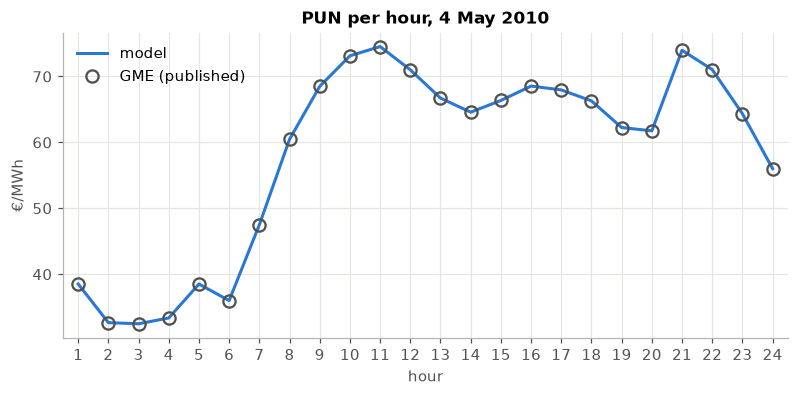

hour,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
pun_model,38.52,32.65,32.48,33.36,38.51,36.0,47.5,60.463068,68.498829,73.130026,...,66.35569,68.543706,67.958972,66.299237,62.250964,61.75337,73.973516,71.045257,64.348253,56.011383
pun_gme,38.52,32.65,32.48,33.36,38.51,36.0,47.5,60.463068,68.498829,73.130026,...,66.35569,68.543706,67.958972,66.299237,62.250964,61.75337,73.973516,71.045257,64.348253,56.011383
pun_diff,0.00,-0.00,0.00,-0.00,0.00,-0.0,-0.0,-0.000000,-0.000000,0.000000,...,0.00000,-0.000000,-0.000000,-0.000000,-0.000000,-0.00000,-0.000000,-0.000000,-0.000000,0.000000


In [5]:
day["pun_diff"] = day["pun_model"] - day["pun_gme"]
zone_diff = pd.concat([day[f"{z}_model"] - day[f"{z}_gme"] for z in PUN_ZONES], axis=1)

print(f"Hours where the model PUN matches GME (|diff| < 1e-5 €/MWh): "
      f"{(day['pun_diff'].abs() < 1e-5).sum()} / {len(day)}")
print(f"Largest PUN difference:          {day['pun_diff'].abs().max():.2e} €/MWh")
print(f"Largest zonal-price difference:  {zone_diff.abs().max().max():.2e} €/MWh")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(day.index, day["pun_model"], color=BLUE, lw=2, label="model")
ax.plot(day.index, day["pun_gme"], ls="none", marker="o", ms=8, mfc="none",
        mec=GREY, mew=1.5, label="GME (published)")
ax.set(title="PUN per hour, 4 May 2010", xlabel="hour", ylabel="€/MWh",
       xticks=range(1, 25), xlim=(0.5, 24.5))
ax.legend(loc="upper left")
plt.show()

day[["pun_model", "pun_gme", "pun_diff"]].round(6).T

## Zonal prices

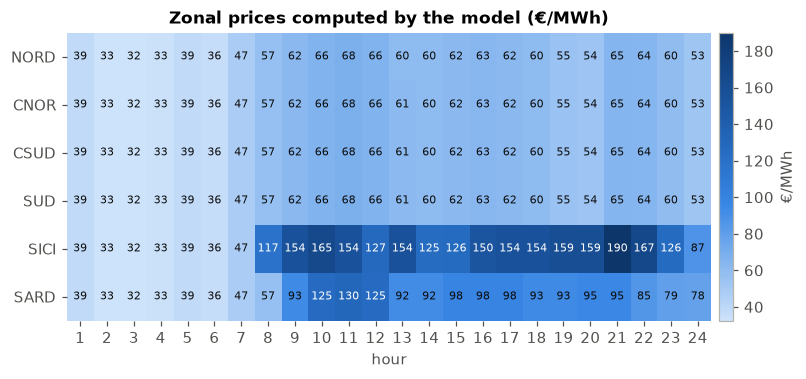

Market split in 17 of 24 hours (hours 8–24).
Number of distinct price areas per hour:


,hours
price areas,
1,7
2,1
3,14
4,2


In [6]:
zonal = day[[f"{z}_model" for z in PUN_ZONES]].rename(columns=lambda c: c[:-6])
day["price_areas"] = zonal.round(2).nunique(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(zonal.T.values, aspect="auto", cmap=SEQ_BLUE)
ax.set(title="Zonal prices computed by the model (€/MWh)", xlabel="hour",
       xticks=range(24), xticklabels=zonal.index, yticks=range(6), yticklabels=PUN_ZONES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
vmin, vmax = zonal.values.min(), zonal.values.max()
for (r, c), v in pd.DataFrame(zonal.T.values).stack().items():
    dark = (v - vmin) / (vmax - vmin) > 0.45
    ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7,
            color="white" if dark else "#0b0b0b")
fig.colorbar(im, ax=ax, pad=0.01, label="€/MWh")
plt.show()

splits = day.loc[day["price_areas"] > 1]
print(f"Market split in {len(splits)} of 24 hours (hours {splits.index.min()}–{splits.index.max()}).")
print("Number of distinct price areas per hour:")
day["price_areas"].value_counts().sort_index().rename_axis("price areas").to_frame("hours")

In [7]:
split_table = pd.DataFrame({
    z: [f"{m:.2f} / {g:.2f}" for m, g in zip(day[f"{z}_model"], day[f"{z}_gme"])]
    for z in PUN_ZONES}, index=day.index).loc[splits.index]
split_table

,NORD,CNOR,CSUD,SUD,SICI,SARD
hour,,,,,,
8,56.94 / 56.94,56.94 / 56.94,56.94 / 56.94,56.94 / 56.94,116.78 / 116.78,56.94 / 56.94
9,62.33 / 62.33,62.33 / 62.33,62.33 / 62.33,62.33 / 62.33,154.01 / 154.01,93.01 / 93.01
10,65.73 / 65.73,65.73 / 65.73,65.73 / 65.73,65.73 / 65.73,165.00 / 165.00,125.01 / 125.01
11,67.90 / 67.90,67.90 / 67.90,67.90 / 67.90,67.90 / 67.90,154.01 / 154.01,130.01 / 130.01
12,65.85 / 65.85,65.85 / 65.85,65.85 / 65.85,65.85 / 65.85,127.44 / 127.44,125.01 / 125.01
13,59.98 / 59.98,60.95 / 60.95,60.95 / 60.95,60.95 / 60.95,154.01 / 154.01,92.01 / 92.01
14,60.00 / 60.00,60.00 / 60.00,60.00 / 60.00,60.00 / 60.00,124.63 / 124.63,92.01 / 92.01
15,61.83 / 61.83,61.83 / 61.83,61.83 / 61.83,61.83 / 61.83,125.71 / 125.71,98.01 / 98.01
16,62.83 / 62.83,62.83 / 62.83,62.83 / 62.83,62.83 / 62.83,150.10 / 150.10,98.01 / 98.01


## Hour 9

In [8]:
HOUR = 9
data = hourly_data[HOUR]
t0 = time.perf_counter()
model = build_model(data)            # kept, to read the flows below
status = solve_model(model)
sol = extract_solution(model, data, status, time.perf_counter() - t0)
print(f"Hour {HOUR} solved in {sol.solve_time_s:.1f} s: PUN = {sol.pun_price:.6f} €/MWh "
      f"(GME {real_prices[HOUR]['PUN']:.6f})")

ids = gme.zone_ids
names = {i: n for n, i in ids.items()}


def executed(bids, shares, zone_id):
    return sum(b.volume * a for b, a in zip(bids, shares) if b.zone_id == zone_id)


balance = pd.DataFrame([{
    "zone": z,
    "price ζ (€/MWh)": sol.zonal_prices[ids[z]],
    "supply (MWh)": executed(data.supply_bids, sol.acceptance.supply, ids[z]),
    "PUN demand (MWh)": executed(data.pun_bids, sol.acceptance.pun, ids[z]),
    "other demand (MWh)": executed(data.demand_bids, sol.acceptance.demand, ids[z]),
    "net import (MWh)": -sum(value(model.F[ids[z], j]) for j in model.Z),
} for z in PUN_ZONES]).set_index("zone")
balance.round(2)

Hour 9 solved in 16.6 s: PUN = 68.498829 €/MWh (GME 68.498829)


,price ζ (€/MWh),supply (MWh),PUN demand (MWh),other demand (MWh),net import (MWh)
zone,,,,,
NORD,62.33,20081.94,24238.38,0,4156.45
CNOR,62.33,2416.97,4744.63,0,2327.66
CSUD,62.33,3512.22,6100.51,0,2588.29
SUD,62.33,1048.15,2999.15,0,1951.00
SICI,154.01,1444.51,2358.51,0,914.00
SARD,93.01,1356.39,1356.39,0,-0.00


### Flows

In [9]:
flows = pd.DataFrame([{
    "from": names[i], "to": names[j], "flow (MWh)": value(model.F[i, j]),
    "capacity (MWh)": value(model.Fmax[i, j]),
} for i in model.Z for j in model.Z if value(model.F[i, j]) > 1e-6])
flows["congested"] = (flows["capacity (MWh)"] - flows["flow (MWh)"]).abs() < 1e-3
flows["Δζ to − from"] = [sol.zonal_prices[ids[t]] - sol.zonal_prices[ids[f]]
                          for f, t in zip(flows["from"], flows["to"])]
flows.sort_values(["congested", "flow (MWh)"], ascending=[False, False]).round(2)

,from,to,flow (MWh),capacity (MWh),congested,Δζ to − from
14,ROSN,SICI,100.00,100.0,True,91.68
6,CSUD,SARD,50.00,50.0,True,30.68
7,SARD,CORS,50.00,50.0,True,0.00
12,SVIZ,NORD,3452.00,10000.0,False,0.00
2,BRNN,SUD,3338.00,5200.0,False,0.00
1,NORD,CNOR,2836.55,3600.0,False,0.00
9,FRAN,NORD,2404.00,10000.0,False,0.00
3,SUD,CSUD,2129.40,3500.0,False,-0.00
8,FOGN,SUD,842.39,2000.0,False,0.00
13,PRGP,SICI,814.00,815.0,False,0.00


### PUN bids

In [10]:
bids = pd.DataFrame([{
    "class": classify(a), "no price limit": b.price >= options.MAX_PRICE,
    "volume (MWh)": b.volume, "accepted (MWh)": b.volume * a,
} for b, a in zip(data.pun_bids, sol.acceptance.pun)])
summary = bids.groupby(["class", "no price limit"]).agg(
    bids=("volume (MWh)", "size"), offered_MWh=("volume (MWh)", "sum"),
    accepted_MWh=("accepted (MWh)", "sum"))
print(f"PUN = {sol.pun_price:.4f} €/MWh")
summary.round(1)

PUN = 68.4988 €/MWh


bids  offered_MWh  accepted_MWh
class no price limit                                 
ITM   False              2          6.0           6.0
      True             434      41791.6       41791.6
OTM   False              6         26.0           0.0

In [11]:
priced = pd.DataFrame([{"price (€/MWh)": b.price, "zone": names[b.zone_id],
                        "volume (MWh)": b.volume, "class": classify(a)}
                       for b, a in zip(data.pun_bids, sol.acceptance.pun)
                       if b.price < options.MAX_PRICE])
priced.sort_values("price (€/MWh)", ascending=False).round(3)

,price (€/MWh),zone,volume (MWh),class
0,80.83,CNOR,3.0,ITM
1,72.75,CNOR,3.0,ITM
4,68.00,SARD,5.0,OTM
2,64.67,CNOR,3.0,OTM
5,61.20,SARD,5.0,OTM
3,56.58,CNOR,3.0,OTM
6,54.40,SARD,5.0,OTM
7,47.60,SARD,5.0,OTM


Bid at 64.67 €/MWh in CNOR is rejected although ζ_CNOR = 62.33, because π = 68.50.

### PUN definition check

In [12]:
check = balance[["price ζ (€/MWh)", "PUN demand (MWh)"]].copy()
check["ζ × demand"] = check["price ζ (€/MWh)"] * check["PUN demand (MWh)"]
weighted = check["ζ × demand"].sum() / check["PUN demand (MWh)"].sum()
print(f"Σ ζ_i·d_i / Σ d_i = {weighted:.6f} €/MWh")
print(f"π from the MILP  = {sol.pun_price:.6f} €/MWh")
print(f"π published      = {real_prices[HOUR]['PUN']:.6f} €/MWh")
check.round(2)

Σ ζ_i·d_i / Σ d_i = 68.498829 €/MWh
π from the MILP  = 68.498829 €/MWh
π published      = 68.498829 €/MWh


,price ζ (€/MWh),PUN demand (MWh),ζ × demand
zone,,,
NORD,62.33,24238.38,1510778.41
CNOR,62.33,4744.63,295732.60
CSUD,62.33,6100.51,380245.04
SUD,62.33,2999.15,186936.89
SICI,154.01,2358.51,363233.82
SARD,93.01,1356.39,126157.83


### Offers and bids (whole market, network ignored)

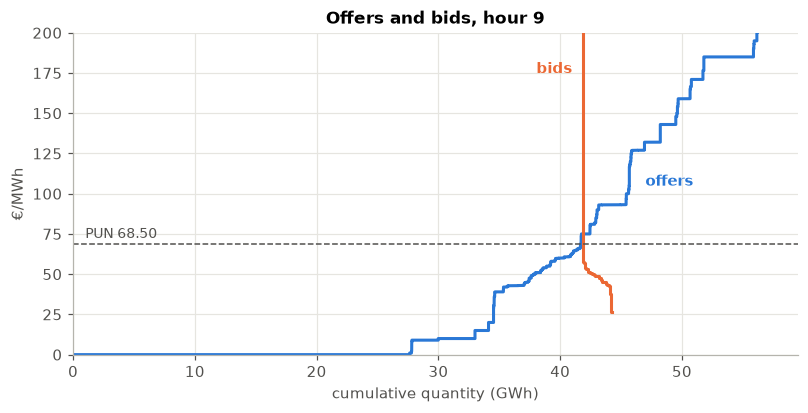

In [13]:
def step_curve(volumes_prices, descending):
    ordered = sorted(volumes_prices, key=lambda vp: vp[1], reverse=descending)
    x, y, total = [0.0], [ordered[0][1]], 0.0
    for v, p in ordered:
        x += [total, total + v]
        y += [p, p]
        total += v
    return x[1:], y[1:]


sx, sy = step_curve([(b.volume, b.price) for b in data.supply_bids], descending=False)
dx, dy = step_curve([(b.volume, b.price) for b in data.pun_bids + data.demand_bids],
                    descending=True)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot([x / 1000 for x in sx], sy, color=BLUE, lw=2)
ax.plot([x / 1000 for x in dx], dy, color=ORANGE, lw=2)
ax.axhline(sol.pun_price, color=GREY, lw=1, ls="--")
ax.text(1, sol.pun_price + 4, f"PUN {sol.pun_price:.2f}", color=GREY, fontsize=9)
ax.text(47, 105, "offers", color=BLUE, fontsize=10, fontweight="bold")
ax.text(41, 175, "bids", color=ORANGE, fontsize=10, fontweight="bold", ha="right")
ax.set(ylim=(0, 200), xlim=(0, max(sx[-1], dx[-1]) / 1000), xlabel="cumulative quantity (GWh)",
       ylabel="€/MWh", title=f"Offers and bids, hour {HOUR}")
plt.show()

## Solve times

Hour 9: 5833 variables (160 binary), 5788 constraints


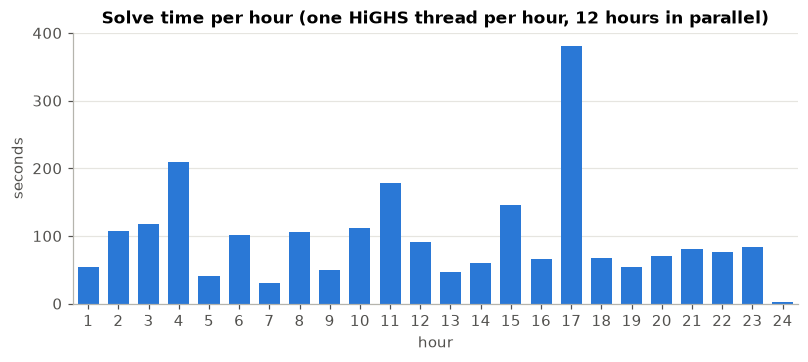

Total: 2337 s of solver time; median 79 s, max 381 s per hour


In [14]:
n_vars = sum(1 for v in model.component_data_objects(Var) if not v.fixed)
n_bin = sum(1 for v in model.component_data_objects(Var) if not v.fixed and v.is_binary())
n_con = sum(1 for _ in model.component_data_objects(Constraint, active=True))
print(f"Hour {HOUR}: {n_vars} variables ({n_bin} binary), {n_con} constraints")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.bar(day.index, day["solve_time_s"], color=BLUE, width=0.7)
ax.set(title="Solve time per hour (one HiGHS thread per hour, 12 hours in parallel)",
       xlabel="hour", ylabel="seconds", xticks=range(1, 25), xlim=(0.5, 24.5))
ax.grid(axis="x", visible=False)
plt.show()
print(f"Total: {day['solve_time_s'].sum():.0f} s of solver time; "
      f"median {day['solve_time_s'].median():.0f} s, max {day['solve_time_s'].max():.0f} s per hour")